Jeremy Barton<br>
Professor Neugebauer<br>
07/01/2026<br>
DSC-630-T301

## Appendix

1. [Data Cleaning](#1-data-cleaning)
2. [Feature Scaling](#2-feature-scaling)
3. [Silhouette Score](#3-silhoutte-score)
4. [Choosing k, Showing Score](#4-choosing-k-showing-score)
5. [Running with Optimal Clusters](#5-running-with-optimal-clusters)
6. [Principal Component Analysis](#6-principal-component-analysis)
7. [Visualizing PCA](#7-visualizing-pca)
8. [Observation and Conclusion](#8-observation-and-conclusion)

# Clustering Algorithms: K-Means & PCA

This notebook will apply K-Means clustering and PCA transformation to a dataset of ALS patients. Visualizations will be provided to show the relationships between and within the clusters.

Additionally, this analysis is preparing to feed labels to a supervised model as part of an ML pipeline. It will use these labels to predit the median functional status of an ALS patient compared to other patients in the study group.

In [21]:
# Imports and preprocessing
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

als_df = pd.read_csv("/home/nunya/Documents/GitHub/DSC630/Week4/als_data.csv")

## 1) Data Cleaning
Remove any data that is not relevant to the patient’s ALS condition.

Before starting a pipeline, the data will be cleaned to remove any data that is not relevant to a patient's ALS condition.

There are four main columns that are not related to ALS and should be dropped. They are `ID`, `Gender_mean`, `SubjectID`, and `Age_mean`. Additionally, there are multiple versions of the same data appended with `_max`, `_min`, `_range` and `median`. To predict the `ALSFRS_Total_median`, only the median of all other symptoms will be used.

In [22]:
cols_to_drop = [col for col in als_df.columns if col.endswith(('_max', '_min', '_range'))]                   
als_df = als_df.drop(columns=["ID","Gender_mean","SubjectID","Age_mean"] + cols_to_drop) 
#als_df

## 2) Feature Scaling
Apply a standard scalar to the data.

Before jumping into modeling, it is important to apply a scalar so data is standardize for machine learning. In it's raw form, the value of features may have different ranges and units which can cause problems for machine learning models that expect the data in a specific format.

<b>Choosing a Scaler</b>

Selecting the right scalar primarily depends on three factors:

1) Does the data follow a normal distribution?
2) How skewed is the data?
3) Are there any outliers, and if so how many and what is their significance? (Can they be dropped?)

Due to computational constraints the `ydata_profile` cannot be ran to help identify an appropriate scalar. This notebook submitted for an assignment will use the StandardScaler.

Because the data follows a roughly normal distribution, the <b>StandardScaler</b> will be used.

Separating X and y, to `fit_transform()` on the training data and to only `transform()` on the testing data. This is to prevent the training data from leaking into the testing data.

In [23]:
X = als_df.drop(columns="ALSFRS_Total_median")
y = als_df["ALSFRS_Total_median"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

With the data split we can now train the model. <b>Note this isn't part of the current notebook requirements, but preparing for the next steps in the pipeline.</b>

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Taking another look at the data, it is now scaled with mean ~0 and standard deviation ~1, as we would expect with the StandardScaler.

In [25]:
pd.DataFrame(X_train_scaled, columns=X_train.columns).describe().loc[["min", "max"]]

,Albumin_median,ALSFRS_slope,ALT.SGPT._median,AST.SGOT._median,Bicarbonate_median,Blood.Urea.Nitrogen..BUN._median,bp_diastolic_median,bp_systolic_median,Calcium_median,Chloride_median,...,mouth_median,onset_delta_mean,onset_site_mean,Platelets_median,Potassium_median,pulse_median,respiratory_median,Sodium_median,trunk_median,Urine.Ph_median
min,-3.498037,-5.750424,-1.597879,-2.105320,-3.380791,-2.252602,-3.427444,-3.248442,-3.387561,-5.633281,...,-3.462593,-4.441927,-1.913151,-3.149362,-4.797003,-3.038964,-5.945645,-6.794532,-2.276111,-1.124009
max,2.679514,3.066513,10.218317,7.463527,5.702290,4.693123,3.977417,4.135461,5.137639,3.168507,...,0.821114,1.639296,2.871071,5.450138,3.684029,4.057509,0.657584,3.295144,1.438156,5.182857


## 3) Silhoutte Score
Create a plot of the cluster silhouette score versus the number of clusters in a K-means cluster.

A Silhoutte Score shows how well each data point fits wihtin its assign cluster and how well it is separated from other cluster. For each point, two main quantites are calculated.

<b>Intra-cluster distance:</b> Average distance betwene the data point and all other points in the same cluster. Small values indicate close alignment with its cluster.

<b>Nearest-cluster distnace:</b> Average distnace between the data point and all points in the nearest neighboring cluster. For this metric, a larger value means the point is well-separated from other clusters.

In [26]:
model = KMeans(n_clusters=4, random_state=42)
predicted_labels = model.fit_predict(X_train_scaled)

In the above cell, the model was established using KMeans with 4 clusters and at a random state of 42.

Calculating the score.

In [27]:
silhouette_val = silhouette_score(X_train_scaled, predicted_labels)
print("Silhouette Score:", silhouette_val)

Silhouette Score: 0.06966106636090323


A score of .070 isn't great. An earlier attempt of this notebook included the _min, _max and range fields, which gave a score of around .03. This is absolutely an improvement, although not impressive.

First let's find the ideal k-range.

In [28]:
print(int(np.sqrt(len(X_test_scaled))))

21


Square rooting the test set (with 445 rows) results in <b>21 being the max k value.</b>

In [29]:
k_range = range(2, 21)
scores = []

# Iterate through k_range, applying KMeans
#   to each of the 21 observations
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    # predit labels with .fit_predit on the scaled trianing data
    labels = km.fit_predict(X_train_scaled)
    # add the results to the "score"
    scores.append(silhouette_score(X_train_scaled, labels))

Creating the plot.

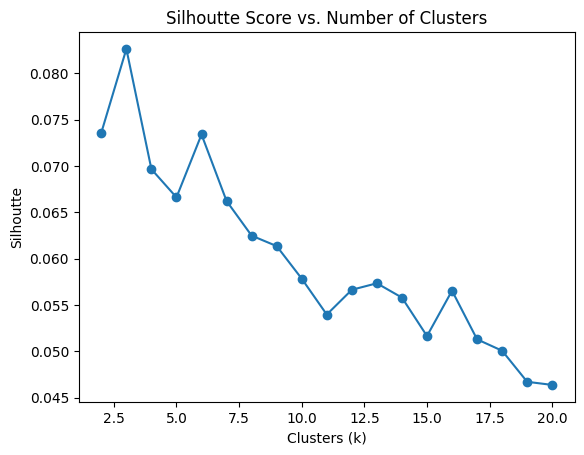

In [30]:
plt.plot(k_range, scores, marker='o')
plt.xlabel("Clusters (k)")
plt.ylabel("Silhoutte")
plt.title("Silhoutte Score vs. Number of Clusters")
plt.show()

## 4) Choosing k, showing score
Use the plot created in (3) to choose an optimal number of clusters for K-means. Justify your choice.

A k-value should be selected by identifying the tallest hump after the initial narrow drop. According to the line graph above, the idea k value looks to be <b>6</b> with a silhoutte score of <b>.073</b>. When more clusters are added, the line drops sharply never to return above 0.08.

In [31]:
print(f"Silhouette Score at k=6: {scores[4]:.4f}") # Using 4 because k starts at 2                                                  

Silhouette Score at k=6: 0.0734


## 5) Running with optimal clusters
Fit a K-means model to the data with the optimal number of clusters chosen in part (4).

Since 6 is the optimal cluster for K-Means, the model will be re-ran with k=6.

In [32]:
model = KMeans(n_clusters=6, random_state=42)
predicted_labels = model.fit_predict(X_train_scaled)

The results are what was seen in the plot - the silhoutte score at 6 clusters is .073.

In [33]:
silhouette_val = silhouette_score(X_train_scaled, predicted_labels)
print("Silhouette Score:", silhouette_val)

Silhouette Score: 0.07340840912939584


## 6) Principal Component Analysis
Fit a K-means model to the data with the optimal number of clusters chosen in part (4).

This PCA reduces the data to 2 principal components. It finds combinations of original features that expalin the most variantion in the data.

In [34]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)
print(X_pca[2:])

[[-0.34702905 -0.47137374]
 [-2.58424889  0.59881835]
 [-0.62107446 -2.84711222]
 ...
 [ 2.88071465 -0.11619326]
 [ 0.86186912  0.11514071]
 [-0.15947896  0.58845395]]


In [35]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))

Explained variance: [0.10843566 0.10240991]
Cumulative: [0.10843566 0.21084557]


## 7) Visualizing PCA
Make a scatterplot the PCA transformed data coloring each point by its cluster value.

Creating a scatterplot from the PCA transformed data. Each point is coloed by its cluster value.

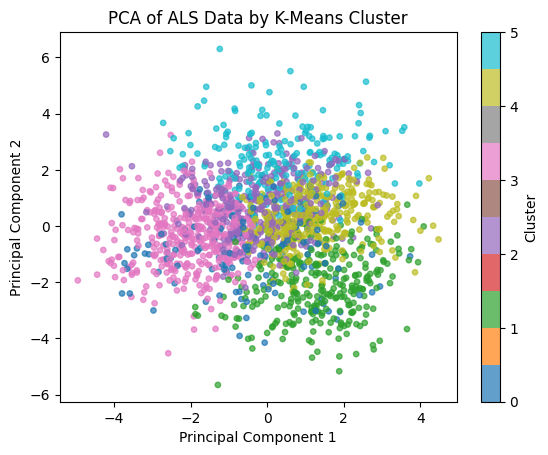

In [36]:
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=predicted_labels, cmap='tab10', s=15, alpha=0.7)
plt.colorbar(scatter, label='Cluster')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of ALS Data by K-Means Cluster')
plt.show()

#### Measuring the effectivness of PCA

## 8) Summary
Summarize your results and make a conclusion.

From the PCA plot above, it appears that the clusters bleed heavily into each other. K-Means clustering did not find strong groupings in this ALS dataset. This is consistent with the very weak silhouette score of .073 and a higher score would show more distingished, separated clusters.

A way to visualize how effective PCA is a Cumulative Explain Variance Plot. It shows the proporation of the dataset's variance that is cumulatively explained by each component. In other words, when performing PCA, data is transferred into a new coordinate system with axes ranked by how well the capture the variance in the data. A Cumulative Explained Variance plot shows at a glance how many components are needed to explain a meaningful portion of the data's total variance. 

In this case, the plot reveals that two components account for only 21.1% of the total variance. This means the 2D scatter plot leaved behind roughly 79% of the data's structure. To capture 90% of the variance, signifiantly more components would be required.

This plot visually justifies why the cluster boundries appear blurry int he PCA scatter plot above.

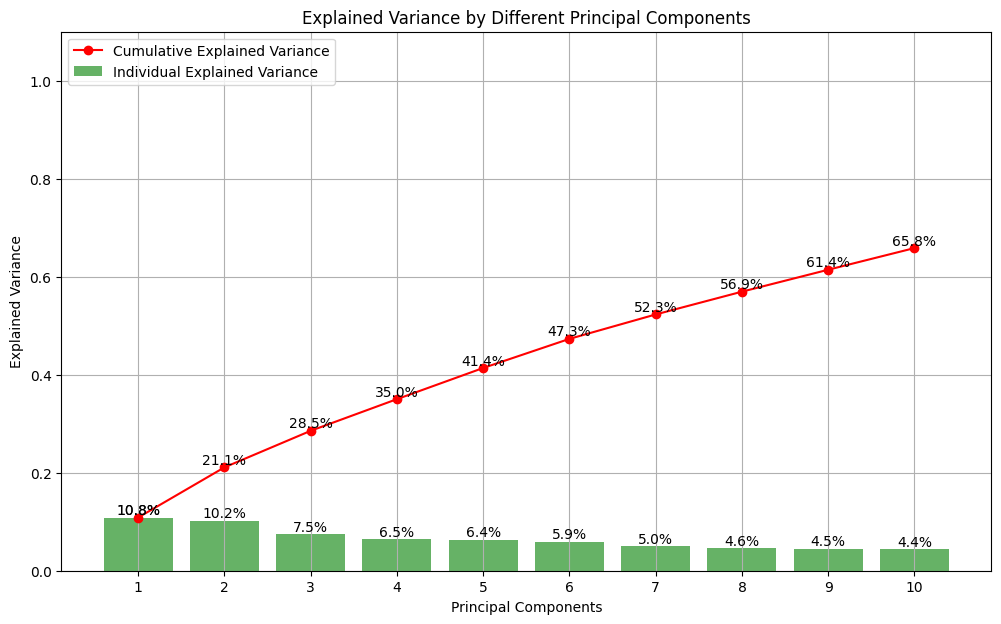

In [37]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

n_show = 10
# individual varinaces
iv = pca_full.explained_variance_ratio_[:n_show]
# cumulative variance
cv = np.cumsum(iv)

plt.figure(figsize=(12, 7))
bars = plt.bar(range(1, n_show + 1), iv, alpha=0.6, color='g', label='Individual Explained Variance')
plt.plot(range(1, n_show + 1), cv, marker='o', linestyle='-', color='r',
         label='Cumulative Explained Variance')

# iterate through each bar to set the height based
#   on the individual variances explain by each principal compnent added
for i, (bar, cum_val) in enumerate(zip(bars, cv)):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{iv[i]*100:.1f}%',
             ha='center', va='bottom')
    plt.text(i + 1, cum_val, f'{cum_val*100:.1f}%', ha='center', va='bottom')


# creating the plot
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance')
plt.title('Explained Variance by Different Principal Components')
plt.xticks(range(1, n_show + 1))
plt.legend(loc='upper left')
plt.ylim(0, 1.1)
plt.grid(True)
plt.show()

Looking very closely at the variance plot, at 2 PCs the cumulative variance is at 21.1%. This is not where the most of the data can be explained though. Only after 4 PCs does the line start to plataeu, indicating four prinipal components are needed to explain the data's total variance with the selected predictor and target variables.

Quick, let's take a look at what a PCA based on 4 PCs would look like.

Explained variance (4 components): [0.10843566 0.10240991 0.07462421 0.06464705]
Cumulative: [0.10843566 0.21084557 0.28546978 0.35011683]


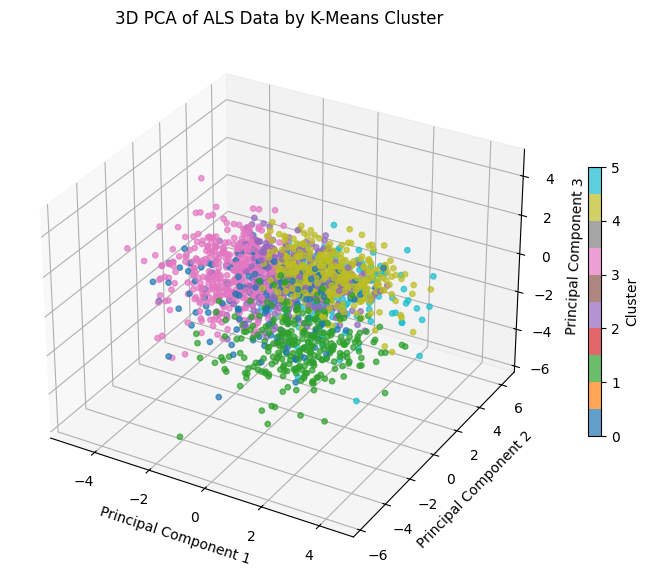

In [38]:
pca4 = PCA(n_components=4)
X_pca4 = pca4.fit_transform(X_train_scaled)

print("Explained variance (4 components):", pca4.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca4.explained_variance_ratio_))

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(X_pca4[:, 0], X_pca4[:, 1], X_pca4[:, 2],
                c=predicted_labels, cmap='tab10', s=15, alpha=0.7)

plt.colorbar(sc, ax=ax, label='Cluster', shrink=0.5)
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D PCA of ALS Data by K-Means Cluster')
plt.show()

Although the above looks similar to the plot with two PCs, we can now see the full picture of cumulative explained variance with the highest meaningful number of PCs. In other words, even when given more PCs to work with, the clusters still do not separate cleanly, which confirms that the overlap seen in the 2D plot was not simply an artifact of losing information during dimensionality reduction. The data itself does not contain strong natural groupings, regardless of how many components are used to represent it.

## 8) Observation and Conclusion

There were two goals of this notebook, the first was to visualize relationships between clusters in a K-Means model using PCA reduce dimentionality and expalin how much of the variance can be explained by 2 PCs. The other goal was to prepare to to predict the median functional status of ALS patients compared to other patients in the study group. The ALS patient dataset was stripped of unrelated columns and only the median version of each symptom column was kept. This may have not been the correct approach though because after running K-Means clustering and performing a PCA with 2 principal components, roughly only 21% of the variance could be explained. A Cumulative Explained Variance plot revealed that 2 PCs was not optimal for explaining full variance of the data. K-means and PCA were ran again with 4 PCs, but this hardly changed the results of the overlapping clusters. Therefore it can be concluded that the variables selected to show relationships between K-means clusters and to target `ALSFRS_Total_median` may not have been correct.

Next steps are to revisit the variables being used to target the total median status. Perhaps including the `_range`, `_min`, or `max` would have produced better results. Once this is achieved, the labels produced from the unsupervised learning model can be inputs for a supervised learning model. This is the reason a train_test_split exists in this notebook; to prepare for the logical next step in a machine learning pipeline.